In [50]:
!pip install Boruta

In [51]:
%reset -f

#We import the relevant python packages
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
from collections import Counter
import matplotlib.pyplot as plt
from skimage.filters import threshold_otsu

warnings.filterwarnings("ignore", category=UserWarning)

from boruta import BorutaPy
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import RFE
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, cross_val_score, RepeatedStratifiedKFold

In [ ]:
#We import the datasets and explore them.
df_xpr = pd.read_csv("data\TGCA_BRCA_clinical_filtered.small.csv" , index_col = 0)
df_clinical = pd.read_csv("data\TGCA_BRCA_clinical_filtered.small.csv" , index_col = 0)

print("Shape of df_xpr:", df_xpr.shape)
print("Shape of df_clinical:", df_clinical.shape)

Shape of df_xpr: (60660, 334)
Shape of df_clinical: (332, 3)


In [54]:
df_xpr.gene_type.unique()

array(['protein_coding', 'transcribed_unitary_pseudogene',
       'transcribed_unprocessed_pseudogene', 'processed_pseudogene',
       'lncRNA', 'polymorphic_pseudogene', 'unprocessed_pseudogene',
       'transcribed_processed_pseudogene', 'IG_V_pseudogene',
       'unitary_pseudogene', 'TR_V_pseudogene', 'IG_V_gene', 'snRNA',
       'miRNA', 'misc_RNA', 'snoRNA', 'rRNA_pseudogene', 'rRNA',
       'TR_V_gene', 'Mt_tRNA', 'Mt_rRNA', 'IG_C_gene', 'IG_J_gene',
       'TR_J_gene', 'TR_C_gene', 'TR_J_pseudogene', 'IG_D_gene',
       'ribozyme', 'IG_C_pseudogene', 'TR_D_gene', 'TEC',
       'IG_J_pseudogene', 'scRNA', 'scaRNA',
       'translated_processed_pseudogene', 'vault_RNA', 'sRNA',
       'translated_unprocessed_pseudogene', 'pseudogene', 'IG_pseudogene'],
      dtype=object)

There are different kinds of gene_type. We process a first level of filtering based on this. Pseudogenes are non-codinng DNA sequences, so we can safely remove them.

In [55]:
df_xpr_filtered1 = df_xpr.loc[~df_xpr["gene_type"].str.contains("pseudogene", case=False, na=False)].copy()
df_xpr_filtered1.shape

(45401, 334)

Now that we removed ~ 15k entries we proceed with a less prior knowledge filtering.
First, we perform univariate filtering based on the variance of the genes.

In [56]:
X_xpr = df_xpr_filtered1.loc[ :, df_clinical.index].transpose()
y = df_clinical.poor_prognosis

In [57]:
variance = np.log10(1 + X_xpr.var())

(0.0, 1000.0)

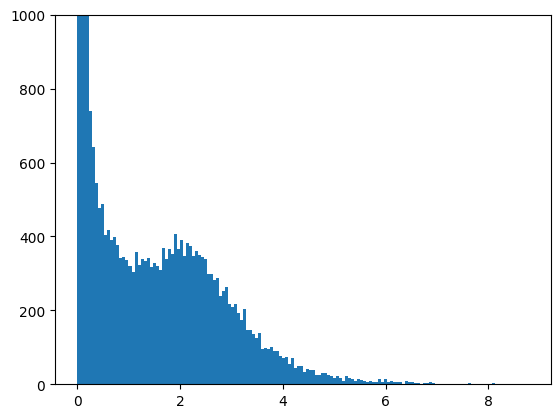

In [58]:
plt.hist(variance.values, bins=150);
plt.ylim(0, 1000)

The distribution seems to be bimodal. One idea would be to remove the genes close to 0 as those are likely to be non informative. To keep an naive approach, we could keep the genes that are above the antimode. To do so, we borrow from image processing the Otsu method and use it to find a threshold that separates the two modes of the distribution.

(0.0, 1000.0)

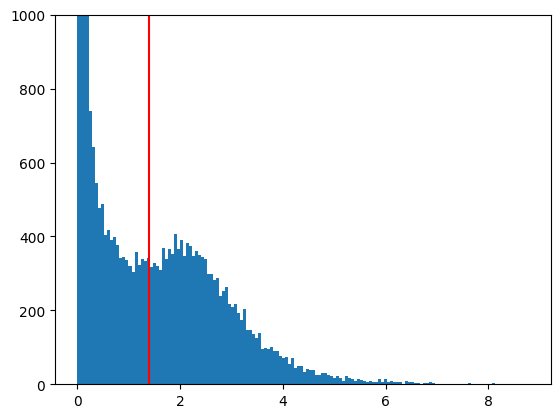

In [59]:
plt.hist(variance.values, bins=150)
plt.axvline(threshold_otsu(variance.values), color='r')
plt.ylim(0, 1000)

In [60]:
X_xpr_filtered = X_xpr.loc[:, variance > threshold_otsu(variance.values)]
X_xpr_filtered.shape

(332, 12310)

This approach works well and reduces the dataset to ~12k features. However, 12k features is still a large number, so we want to reduce it further to obtain a more manageable dataset. We also want a more sophisticated filtering step that accounts for relationships among multiple features. To do this, we rank features by importance from a RandomForestClassifier (hyperparameters tuned with GridSearchCV) and retain those with non-zero importance.
The obtained dataset is then fed to Boruta.

In [ ]:
# We define the function to run Boruta

def run_boruta(X, y):
  rf = RandomForestClassifier(
      n_estimators=500,
      random_state=123,
      n_jobs=-1,
      class_weight="balanced"
      )

  boruta_selector = BorutaPy(
      estimator=rf,
      n_estimators="auto",
      max_iter=250,
      random_state=123,
      verbose=0
      )

  boruta_selector.fit(X.to_numpy(), y.to_numpy())

  Xf = boruta_selector.transform(np.array(X))

  boruta_mask = boruta_selector.support_
  X_boruta = X.loc[:, boruta_mask]
  boruta_genes = X_boruta.columns

  return boruta_genes

In [61]:
# We define the function to run first GridSearchCV/RF importance filtering and then Boruta

def select_features(X_train, y_train, n_keep=500):

    # RF importance filter
    rf = RandomForestClassifier(
        n_estimators=500,
        max_depth=2,
        class_weight="balanced",
        random_state=123,
        n_jobs=-1
    )
    rf.fit(X_train, y_train)

    importances = pd.Series(rf.feature_importances_, index=X_train.columns)
    top_genes = importances.nlargest(n_keep).index
    X_rf_fold = X_train[top_genes]

    # Boruta
    boruta_genes = run_boruta(X_rf_fold, y_train)
    return boruta_genes

In [ ]:
# We define a function to evaluate thepredictions of the model with cross-validation.
# Usually, splitting the data into a training and a test set is important to detect
# overfitting and obtain a reliable estimate of performance on unseen data.
# However, since we have few samples, a single split would leave only a small test set.
# For this reason, we use RepeatedStratifiedKFold, in which every sample is used for testing once per repeat.
# Feature selection is performed inside each fold, using only the training data.

def cv_score(X, y, n_splits=2, n_repeats=1):

    splitter = RepeatedStratifiedKFold(
        n_splits=n_splits,
        n_repeats=n_repeats,
        random_state=123
        )
    
    fold_scores = []
    fold_gene_counts = Counter()
    
    for fold, (train_idx, test_idx) in enumerate(splitter.split(X, y)):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        
        genes = select_features(X_train, y_train)
        fold_gene_counts.update(genes)
        
        clf = RandomForestClassifier(
            n_estimators=500,
            random_state=123,
            n_jobs=-1,
            class_weight="balanced"
            )
        
        clf.fit(X_train[genes], y_train)
        
        proba = clf.predict_proba(X_test[genes])[:, 1]
        score = roc_auc_score(y_test, proba)
        print(f"fold {fold}: {len(genes)} genes, AUC={score:.3f}")
        
        fold_scores.append(score)
    print(
        f"\n CV ({n_repeats}x{n_splits}-fold) mean AUC: "
        f"{np.mean(fold_scores):.3f} +/- {np.std(fold_scores):.3f}"
        )
    
    return fold_scores, fold_gene_counts

In [ ]:
fold_scores, fold_gene_counts = cv_score(X_xpr_filtered, y, n_splits=5, n_repeats=2)

The mean AUC indicates a rather weak predictive performance.
We examine the genes selected in at least 5 folds, as these are likely to be the most reliable.

In [68]:
robust_genes = pd.Series(fold_gene_counts).sort_values(ascending=False)
robust_genes.name = "n_folds_selected"

In [70]:
genes_selected_x_folds = robust_genes[robust_genes >= 5].index

selected_genes_expression = X_xpr_filtered.loc[:, X_xpr_filtered.columns.intersection(genes_selected_x_folds)]

prognosis_analysis = pd.DataFrame({
    "gene_name": df_xpr[['gene_name']].reindex(selected_genes_expression.columns)["gene_name"],
    'n_folds_selected': robust_genes.loc[selected_genes_expression.columns],
    "good_prognosis_mean": selected_genes_expression.loc[~y].mean(),
    "poor_prognosis_mean": selected_genes_expression.loc[y].mean(),
    "difference_poor_minus_good": selected_genes_expression.loc[y].mean() - selected_genes_expression.loc[~y].mean()
})

prognosis_analysis.sort_values("difference_poor_minus_good", ascending=False)

,gene_name,n_folds_selected,good_prognosis_mean,poor_prognosis_mean,difference_poor_minus_good
ENSG00000102144.15,PGK1,9,280.490426,397.753087,117.262661
ENSG00000131174.7,COX7B,5,94.640205,108.775423,14.135218
ENSG00000103485.19,QPRT,5,26.635433,38.789307,12.153874
ENSG00000152684.11,PELO,6,18.066517,21.632708,3.566191
ENSG00000043355.12,ZIC2,5,2.626546,3.939921,1.313374
ENSG00000135211.6,TMEM60,5,77.684792,66.956732,-10.728061
ENSG00000186868.16,MAPT,6,36.864472,23.019008,-13.845464
ENSG00000104368.19,PLAT,5,88.087803,56.136241,-31.951562
ENSG00000179241.13,LDLRAD3,7,86.666016,54.364566,-32.301449


The selected genes include both genes associated with poor prognosis (positive values in the "difference_poor_minus_good" column) and genes associated with good prognosis (negative values).

The most frequently selected gene is PGK1, chosen in 9 out of 10 folds. PGK1 encodes a key glycolytic enzyme and has previously been implicated in breast cancer, suggesting it may be a potential prognostic marker.

The second most frequently selected gene is LDLRAD3, chosen in 7 out of 10 folds, and associated with good prognosis. LDLRAD3 has been included in some multi-gene prognostic signatures for breast cancer, but it is not established as a standalone clinical biomarker of prognosis.